# Importações

In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from dotenv import load_dotenv

from sqlalchemy.engine import URL
from sqlalchemy import create_engine

load_dotenv()

SEED = 723

In [2]:
url = URL.create(
    drivername="postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASS"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
)

engine = create_engine(url)

query = "SELECT * FROM gold.delivery_delay;"

In [3]:
df = pd.read_sql("SELECT * FROM gold.delivery_delay", engine)

df.shape

(96456, 22)

# Definindo treino e teste

In [4]:
X = df.drop(columns=["order_id", "is_delayed"])
y = df["is_delayed"]

In [5]:
# iremos dividir por data de corte
# onde o modelo é treinado com dados passados e testado com dados futuros.
# tendo em vista que is_delayed tem classes desbalanceadas
cutoff_date = pd.Timestamp("2018-06-01")

df["purchase_date"] = pd.to_datetime(df["purchase_date"])

train_df = df[df["purchase_date"] < cutoff_date].copy()
test_df = df[df["purchase_date"] >= cutoff_date].copy()

print("Treino:", train_df.shape, "\nTeste:", test_df.shape)

Treino: (77853, 22) 
Teste: (18603, 22)


In [6]:
print("Período treino:")
print(train_df["purchase_date"].min(), "→", train_df["purchase_date"].max())

print("\nPeríodo teste:")
print(test_df["purchase_date"].min(), "→", test_df["purchase_date"].max())

Período treino:
2016-09-15 00:00:00 → 2018-05-31 00:00:00

Período teste:
2018-06-01 00:00:00 → 2018-08-29 00:00:00


In [7]:
drop_cols = ["order_id", "is_delayed", "purchase_date"]

X_train = train_df.drop(columns=drop_cols)
y_train = train_df["is_delayed"]

X_test = test_df.drop(columns=drop_cols)
y_test = test_df["is_delayed"]

# Pré Processamento

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import ColumnTransformer

In [9]:
numeric_features = ["approval_time_hours", "estimated_delivery_days", "item_count", "unique_product_count",
                    "seller_count", "total_price", "total_freight", "total_weight_g", "total_volume_cm3",
                    "distance_km", "payment_count", "payment_type_count", "max_installments", "category_count"]

categorical_features = ["purchase_month", "purchase_day_of_week", "purchase_hour",
                        "shipping_state_type", "main_product_category",]

In [ ]:
# criando os pipelines para pré-processamento dos dados numéricos e categóricos
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])

categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore"))])

In [11]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)])

# Modelos

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.pipeline import Pipeline

# metricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, precision_recall_curve,
                             ConfusionMatrixDisplay)

from sklearn.model_selection import TimeSeriesSplit, cross_validate

## Dummy

Usando o dummy como modelo base, pra mostrar como nesse tipo de problema, não podemos confiar apenas na acuracia

In [13]:
dummy_model = Pipeline([("preprocessor", preprocessor),
                        ("classifier", DummyClassifier(strategy="most_frequent"))])

dummy_model.fit(X_train, y_train)

y_pred_dummy = dummy_model.predict(X_test)

Accuracy: 0.9452238886201151
Precision: 0.0
Recall: 0.0
F1: 0.0

Matriz de confusão:


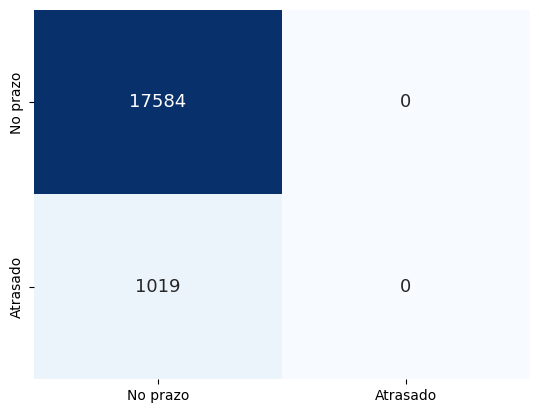

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_dummy))
print("Precision:", precision_score(y_test, y_pred_dummy, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_dummy, zero_division=0))
print("F1:", f1_score(y_test, y_pred_dummy, zero_division=0))

print("\nMatriz de confusão:")
sns.heatmap(confusion_matrix(y_test, y_pred_dummy), annot=True, fmt="d", cmap="Blues",
            xticklabels=["No prazo", "Atrasado"], yticklabels=["No prazo", "Atrasado"],
            annot_kws={"size": 13}, cbar=False)
plt.show()
# 94.5% de acurácia, mas o modelo não consegue identificar nenhum atraso
# pois ele sempre prevê a classe majoritária

# as outras métricas são todas zero
# o que indica que o modelo não é útil para o problema em questão

## Validação Cruzada Temporal (TimeSeriesSplit)

Para avaliar a capacidade de generalização dos modelos, foi utilizada a estratégia de validação cruzada temporal com janela expansiva (expanding window).

Diferentemente da validação cruzada tradicional, essa abordagem preserva a ordem cronológica dos pedidos, garantindo que os modelos sejam treinados com observações anteriores às utilizadas na validação.

**Configuração:**

- Número de folds: 5

- Critério de ordenação: data de compra (purchase_date)

- Estratégia: janela de treinamento expansiva

In [15]:
train_df = train_df.sort_values("purchase_date").reset_index(drop=True)

X_train = train_df.drop(columns=["order_id", "is_delayed", "purchase_date"])

y_train = train_df["is_delayed"]

In [16]:
tscv = TimeSeriesSplit(n_splits=5)

In [17]:
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    fold_train = train_df.iloc[train_idx]
    fold_val = train_df.iloc[val_idx]

    print(f"Fold {fold}")
    print("Treino:", fold_train["purchase_date"].min().date(), 
          "→",
          fold_train["purchase_date"].max().date(), f"({len(fold_train)} pedidos)")

    print("Validação:", fold_val["purchase_date"].min().date(),
          "→",
          fold_val["purchase_date"].max().date(), f"({len(fold_val)} pedidos)")

    print("Atraso treino:", f'{fold_train["is_delayed"].mean():.2%}')

    print("Atraso validação:", f'{fold_val["is_delayed"].mean():.2%}')

    print("-" * 60)

Fold 1
Treino: 2016-09-15 → 2017-06-18 (12978 pedidos)
Validação: 2017-06-18 → 2017-09-27 (12975 pedidos)
Atraso treino: 4.66%
Atraso validação: 4.02%
------------------------------------------------------------
Fold 2
Treino: 2016-09-15 → 2017-09-27 (25953 pedidos)
Validação: 2017-09-27 → 2017-12-04 (12975 pedidos)
Atraso treino: 4.34%
Atraso validação: 10.68%
------------------------------------------------------------
Fold 3
Treino: 2016-09-15 → 2017-12-04 (38928 pedidos)
Validação: 2017-12-04 → 2018-02-06 (12975 pedidos)
Atraso treino: 6.45%
Atraso validação: 7.03%
------------------------------------------------------------
Fold 4
Treino: 2016-09-15 → 2018-02-06 (51903 pedidos)
Validação: 2018-02-06 → 2018-04-03 (12975 pedidos)
Atraso treino: 6.60%
Atraso validação: 19.57%
------------------------------------------------------------
Fold 5
Treino: 2016-09-15 → 2018-04-03 (64878 pedidos)
Validação: 2018-04-03 → 2018-05-31 (12975 pedidos)
Atraso treino: 9.19%
Atraso validação: 6.50%

## Regressão Logística

In [18]:
logistic_model = Pipeline([("preprocessor", preprocessor),
                           ("classifier", LogisticRegression(class_weight="balanced",
                                                             max_iter=1000, random_state=SEED))])

In [19]:
scoring = {"precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision",}

In [20]:
logistic_cv = cross_validate(logistic_model, X_train, y_train, cv=tscv,
                             scoring=scoring, n_jobs=-1, return_train_score=False, return_estimator=True)

In [21]:
results = pd.DataFrame({"precision": logistic_cv["test_precision"], "recall": logistic_cv["test_recall"],
                        "f1": logistic_cv["test_f1"],  "roc_auc": logistic_cv["test_roc_auc"],
                        "pr_auc": logistic_cv["test_pr_auc"]})

results.index = [f"Fold {i}" for i in range(1, len(results) + 1)]
results

,precision,recall,f1,roc_auc,pr_auc
Fold 1,0.045028,0.902111,0.085774,0.628384,0.068341
Fold 2,0.110848,0.743146,0.192920,0.513220,0.115456
Fold 3,0.085392,0.746711,0.153258,0.609718,0.108547
Fold 4,0.275996,0.559275,0.369599,0.633784,0.290009
Fold 5,0.103375,0.344787,0.159060,0.649986,0.116875


In [22]:
results.agg(["mean", "std"])

,precision,recall,f1,roc_auc,pr_auc
mean,0.124128,0.659206,0.192122,0.607018,0.139846
std,0.088640,0.213630,0.106551,0.054370,0.086261


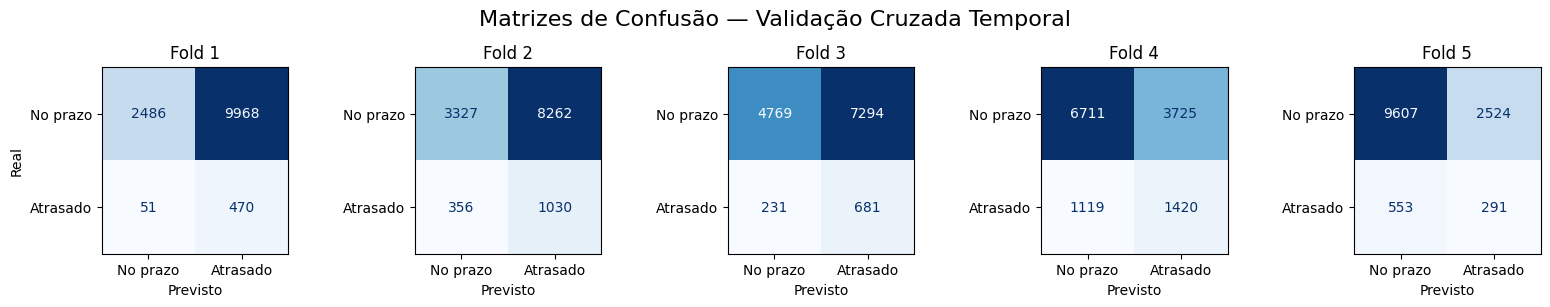

In [23]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3))

for fold, ((train_idx, val_idx), model) in enumerate(
    zip(tscv.split(X_train), logistic_cv["estimator"]), start=1):
    
    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    # Previsões do fold
    y_pred = model.predict(X_val)

    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No prazo", "Atrasado"])
    disp.plot(ax=axes[fold - 1], cmap="Blues", colorbar=False, values_format="d")

    axes[fold - 1].set_title(f"Fold {fold}")
    axes[fold - 1].set_xlabel("Previsto")
    axes[fold - 1].set_ylabel("Real" if fold == 1 else "")

fig.suptitle("Matrizes de Confusão — Validação Cruzada Temporal", fontsize=16)
plt.tight_layout()
plt.savefig("assets/confusion_matrix_folds.png", dpi=300, bbox_inches="tight")
plt.show()

## Random Forest

In [24]:
random_forest_model = Pipeline([("preprocessor", preprocessor),
                                ("classifier", RandomForestClassifier(n_estimators=300,
                                                                      class_weight="balanced",
                                                                      random_state=SEED, n_jobs=-1))])

In [25]:
rf_cv = cross_validate(random_forest_model, X_train, y_train, cv=tscv, scoring=scoring,
                       n_jobs=-1, return_train_score=False, return_estimator=True)

/home/djallen/.pyenv/versions/3.13.0/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [26]:
rf_results = pd.DataFrame({"precision": rf_cv["test_precision"],
                           "recall": rf_cv["test_recall"],"f1": rf_cv["test_f1"],
                           "roc_auc": rf_cv["test_roc_auc"], "pr_auc": rf_cv["test_pr_auc"]})

rf_results.index = [f"Fold {i}" for i in range(1, len(rf_results) + 1)]

rf_results

,precision,recall,f1,roc_auc,pr_auc
Fold 1,0.500000,0.001919,0.003824,0.612709,0.064975
Fold 2,0.000000,0.000000,0.000000,0.588343,0.150260
Fold 3,0.272727,0.006579,0.012848,0.620064,0.114477
Fold 4,0.000000,0.000000,0.000000,0.607813,0.262091
Fold 5,0.400000,0.004739,0.009368,0.590269,0.103455


In [27]:
rf_results.agg(["mean", "std"])

,precision,recall,f1,roc_auc,pr_auc
mean,0.234545,0.002648,0.005208,0.603840,0.139051
std,0.228759,0.002932,0.005741,0.013982,0.075204


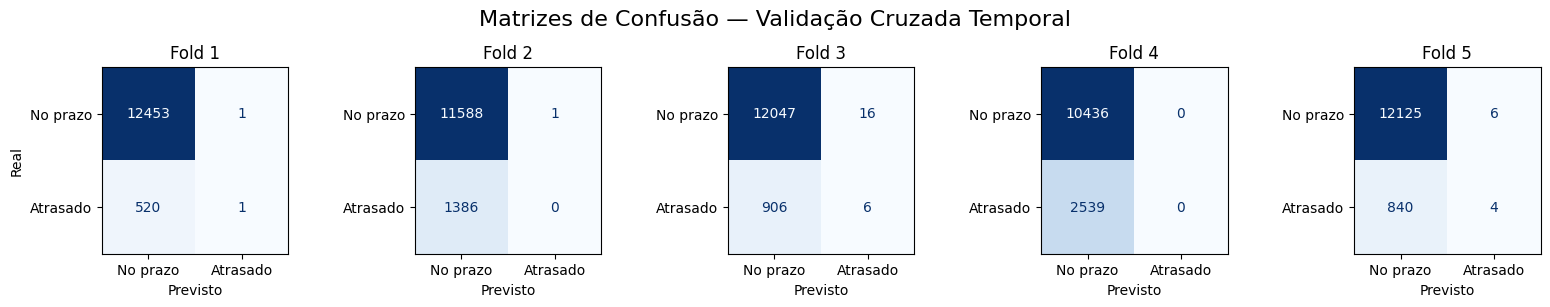

In [28]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3))

for fold, ((train_idx, val_idx), model) in enumerate(
    zip(tscv.split(X_train), rf_cv["estimator"]), start=1):
    
    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    # Previsões do fold
    y_pred = model.predict(X_val)

    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No prazo", "Atrasado"])
    disp.plot(ax=axes[fold - 1], cmap="Blues", colorbar=False, values_format="d")

    axes[fold - 1].set_title(f"Fold {fold}")
    axes[fold - 1].set_xlabel("Previsto")
    axes[fold - 1].set_ylabel("Real" if fold == 1 else "")

fig.suptitle("Matrizes de Confusão — Validação Cruzada Temporal", fontsize=16)
plt.tight_layout()
plt.savefig("assets/confusion_matrix_folds.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
comparison = pd.DataFrame({"Logistic Regression": results.mean(),
                           "Random Forest": rf_results.mean()}).T

comparison

,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.124128,0.659206,0.192122,0.607018,0.139846
Random Forest,0.234545,0.002648,0.005208,0.603840,0.139051


## Hist Gradient Boost

In [30]:
categorical_pipeline_dense = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                                sparse_output=False))])

preprocessor_dense = ColumnTransformer([("num", numeric_pipeline, numeric_features),
                                        ("cat", categorical_pipeline_dense, categorical_features)])

In [31]:
hgb_model = Pipeline([("preprocessor", preprocessor_dense),
                      ("classifier", HistGradientBoostingClassifier(learning_rate=0.1,
                                                                    max_iter=200, random_state=SEED))])

In [32]:
hgb_cv = cross_validate(hgb_model, X_train, y_train, cv=tscv, scoring=scoring,
                        n_jobs=-1, return_train_score=False, return_estimator=True)

/home/djallen/.pyenv/versions/3.13.0/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [34]:
hgb_results = pd.DataFrame({"precision": hgb_cv["test_precision"], "recall": hgb_cv["test_recall"],
                            "f1": hgb_cv["test_f1"], "roc_auc": hgb_cv["test_roc_auc"],
                            "pr_auc": hgb_cv["test_pr_auc"],})

hgb_results.index = [f"Fold {i}" for i in range(1, len(hgb_results) + 1)]

hgb_results

,precision,recall,f1,roc_auc,pr_auc
Fold 1,0.000000,0.000000,0.000000,0.605511,0.063045
Fold 2,0.000000,0.000000,0.000000,0.585614,0.144227
Fold 3,0.166667,0.001096,0.002179,0.606679,0.108020
Fold 4,0.000000,0.000000,0.000000,0.613805,0.262731
Fold 5,0.250000,0.002370,0.004695,0.644876,0.120984


In [35]:
hgb_results.agg(["mean", "std"])

,precision,recall,f1,roc_auc,pr_auc
mean,0.083333,0.000693,0.001375,0.611297,0.139801
std,0.117851,0.001051,0.002082,0.021496,0.074811


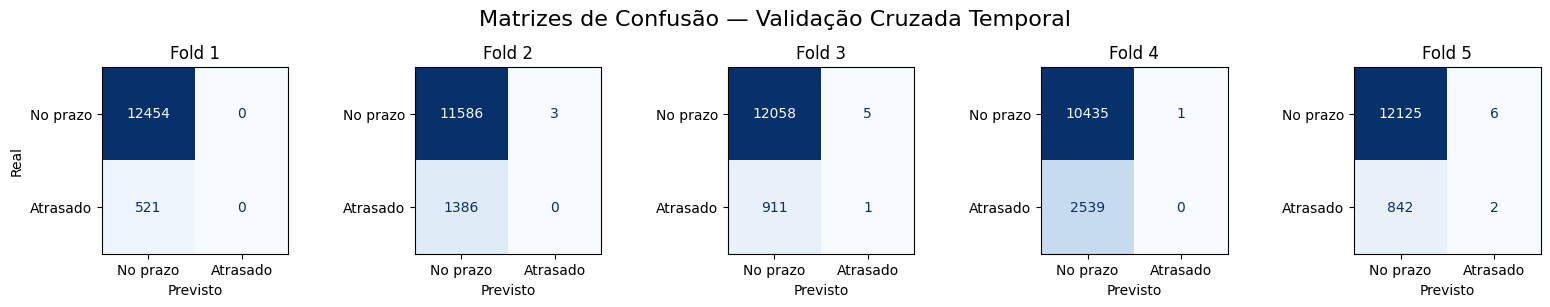

In [37]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3))

for fold, ((train_idx, val_idx), model) in enumerate(
    zip(tscv.split(X_train), hgb_cv["estimator"]), start=1):
    
    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    # Previsões do fold
    y_pred = model.predict(X_val)

    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No prazo", "Atrasado"])
    disp.plot(ax=axes[fold - 1], cmap="Blues", colorbar=False, values_format="d")

    axes[fold - 1].set_title(f"Fold {fold}")
    axes[fold - 1].set_xlabel("Previsto")
    axes[fold - 1].set_ylabel("Real" if fold == 1 else "")

fig.suptitle("Matrizes de Confusão — Validação Cruzada Temporal", fontsize=16)
plt.tight_layout()
plt.savefig("assets/confusion_matrix_folds.png", dpi=300, bbox_inches="tight")
plt.show()

In [36]:
comparison = pd.DataFrame({"Logistic Regression": results.mean(),
                           "Random Forest": rf_results.mean(),
                           "HistGradientBoosting": hgb_results.mean()}).T

comparison

,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.124128,0.659206,0.192122,0.607018,0.139846
Random Forest,0.234545,0.002648,0.005208,0.603840,0.139051
HistGradientBoosting,0.083333,0.000693,0.001375,0.611297,0.139801
